# PPO (Proximal Policy Optimization) Notebook

In [1]:
import sys
sys.path.append("../../RL Policy Sparsification")

In [2]:
import gym, warnings, os, torch, random, gc
import numpy as np
import pandas as pd
from models import PolicyNet, SparsePolicyNet
from rl_utils.ppo import PPOTrainer, train
from  utils import (
    xavier_init_weights, 
    save_model_params, 
    plot_train_performance, 
    plot_result_dataframe,
    run_evaluation,
)
from typing import Union, Optional

warnings.filterwarnings("ignore")
os.environ["ENV_SEED"] = "3407"
RENDER_MODE_ON_EVAL = None
torch.set_default_dtype(torch.float32)

In [3]:
SEED = int(os.environ["ENV_SEED"])
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [4]:
policy_lr = 2.5e-5
value_lr = 2.5e-4
gamma = 0.99
lambda_ = 0.97
epsilon = 0.2
episodes = 400
entropy_coef = 0.007
n_policy_train_steps = 100
n_value_train_steps = 100
hidden_size = 128
max_episode_reward = 500

env_name = "CartPole-v1"
train_env = gym.make(env_name)
results_dir = "../sparsification_results"

observation_space = train_env.observation_space._shape[0]
action_space = train_env.action_space.n

sparsity_penalty_coefs = np.array([1e-05, 5e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1, 5e-1])

In [5]:
def run_train(
        policy_agent: Union[PolicyNet, SparsePolicyNet], 
        value_agent: Union[PolicyNet, SparsePolicyNet],
        policy_optimizer: torch.optim.Optimizer,
        value_optimizer: torch.optim.Optimizer,
        policy_weights_filename: Optional[str]=None,
        save_best_weights: bool=True,
        sparse_penalty_coef: Optional[float]=None,
        plot_performance: bool=True,
    ):

    if isinstance(policy_agent, SparsePolicyNet):
        assert sparse_penalty_coef is not None

    if save_best_weights:
        assert policy_weights_filename is not None
    
    train_env = gym.make(env_name)
    ppo = PPOTrainer(
        policy_agent,
        value_agent, 
        policy_optimizer, 
        value_optimizer, 
        epsilon=epsilon, 
        entropy_coef=entropy_coef, 
        n_policy_train_steps=n_policy_train_steps, 
        n_value_train_steps=n_value_train_steps, 
        sparse_penalty_coef=sparse_penalty_coef
    )

    os.makedirs("../params", exist_ok=True)

    try:
        train_performance, best_rewards = train(
            train_env, 
            ppo, 
            n_episodes=episodes, 
            gamma=gamma, 
            lambda_=lambda_, 
            max_episode_reward=max_episode_reward,
            continue_after_max_reward=False,
            policy_weights_filename=policy_weights_filename,
            save_best_weights=save_best_weights,
            verbose=False,
            close_env=True,
        )
    except KeyboardInterrupt:
        train_env.close()

    if plot_performance:
        plot_train_performance(train_performance, best_rewards)

    convergence_steps = len(train_performance["rewards"])
    return convergence_steps

## Train and Evaluate Dense Policy

  9%|▉         | 36/400 [00:16<02:48,  2.16it/s]


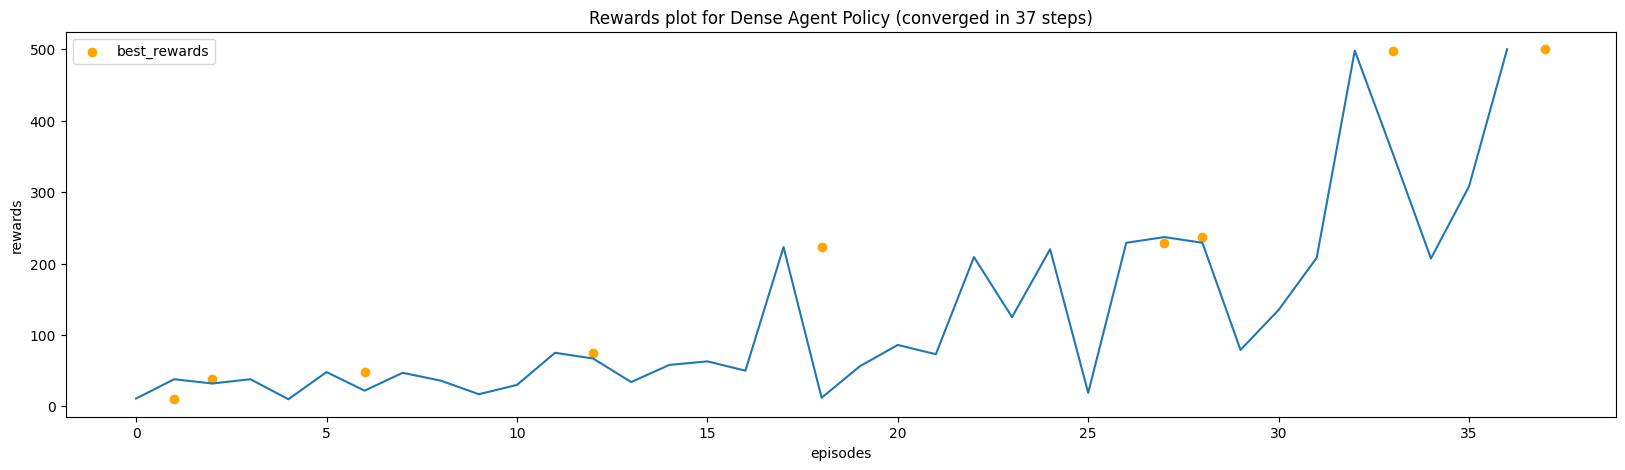

Evaluation reward of policy: 500.0
Average entropy of policy: 0.0295669


(500.0, 0.02956687898337841)

In [6]:
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size)
dense_policy_agent.to(os.getenv("DEVICE"))
dense_value_agent = PolicyNet(observation_space, 1, hidden_size)
dense_value_agent.to(os.getenv("DEVICE"))

dense_policy_agent.apply(xavier_init_weights)
dense_value_agent.apply(xavier_init_weights)

dense_policy_optimizer = torch.optim.Adam(dense_policy_agent.parameters(), lr=policy_lr)
dense_value_optimizer = torch.optim.Adam(dense_value_agent.parameters(), lr=value_lr)
policy_weights_filename = f"{env_name}_PPO_dense_policy_agent.pth.tar"

run_train(
    dense_policy_agent, 
    dense_value_agent, 
    dense_policy_optimizer, 
    dense_value_optimizer, 
    policy_weights_filename, 
    plot_performance=True
)
dense_policy_agent.load_state_dict(torch.load(os.path.join(f"../params/{policy_weights_filename}")))
run_evaluation(gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), dense_policy_agent, verbose=True)

## Train and Evaluate Sparse Policy Against Different Sparsity Coefficents

Training sparse policy with sparsity coef: 1e-05



 21%|██        | 84/400 [01:39<06:15,  1.19s/it]


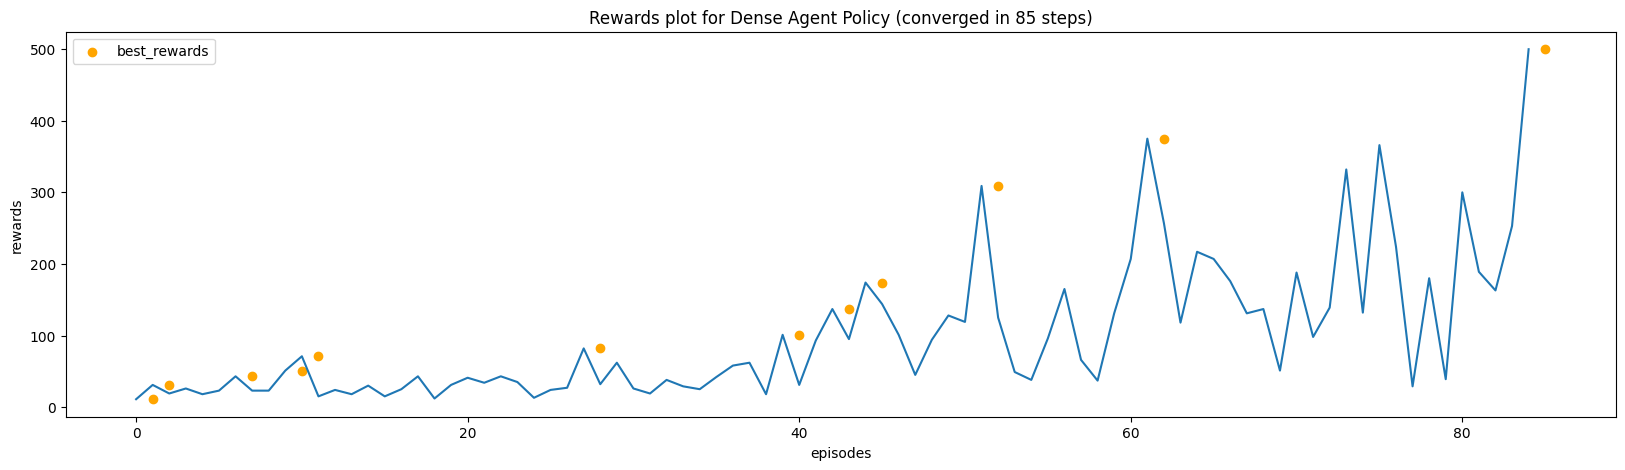

Training sparse policy with sparsity coef: 5e-05



 30%|███       | 120/400 [02:51<06:39,  1.43s/it]


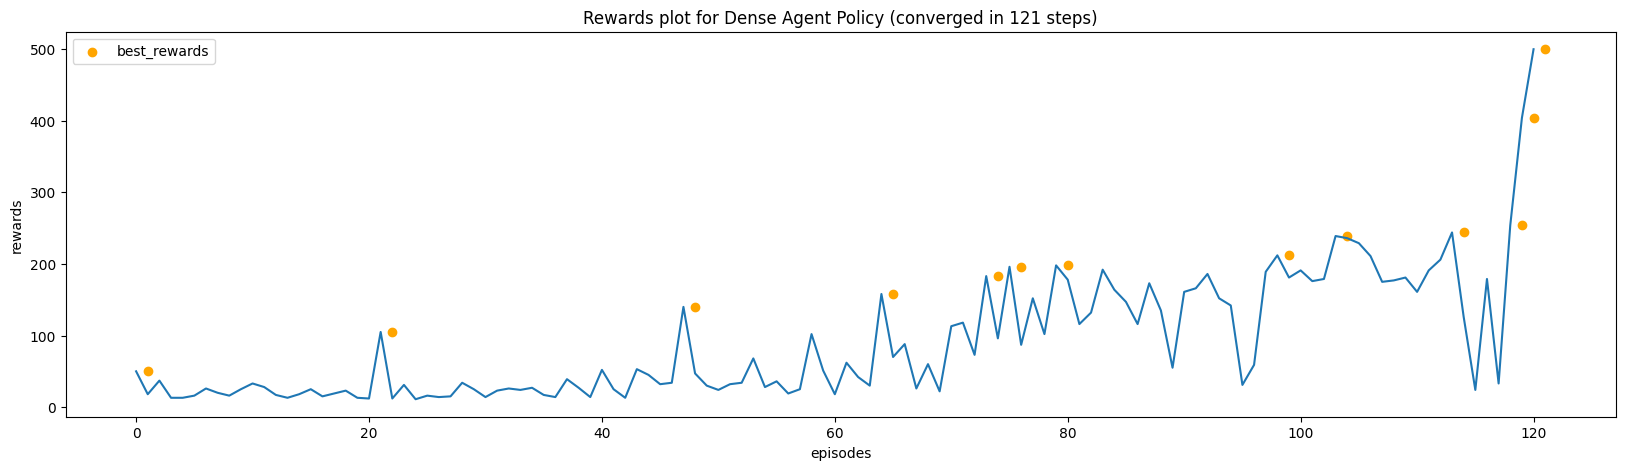

Training sparse policy with sparsity coef: 0.0001



 40%|████      | 160/400 [04:26<06:39,  1.67s/it]


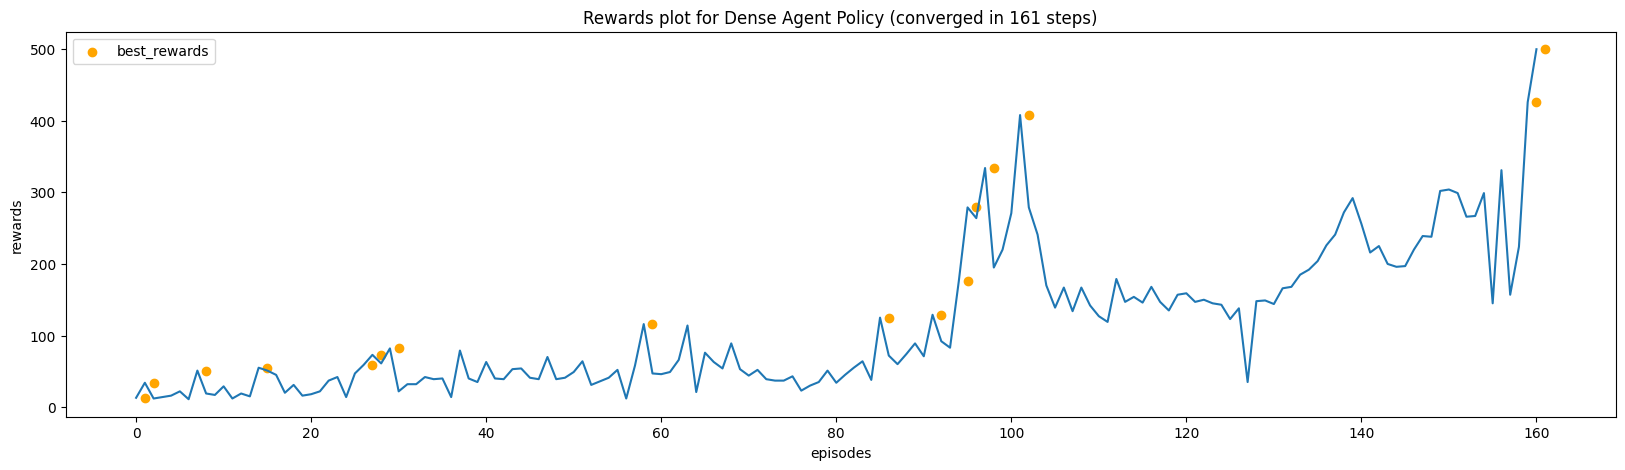

Training sparse policy with sparsity coef: 0.0005



 26%|██▌       | 104/400 [02:48<08:00,  1.62s/it]


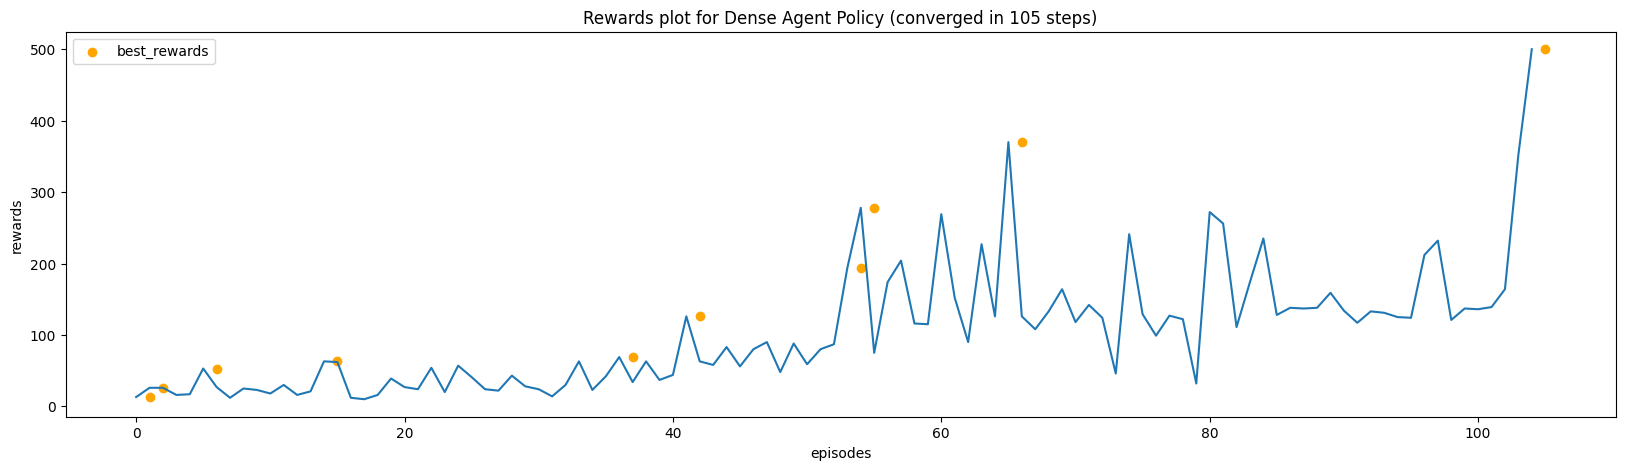

Training sparse policy with sparsity coef: 0.001



 42%|████▏     | 166/400 [04:29<06:19,  1.62s/it]


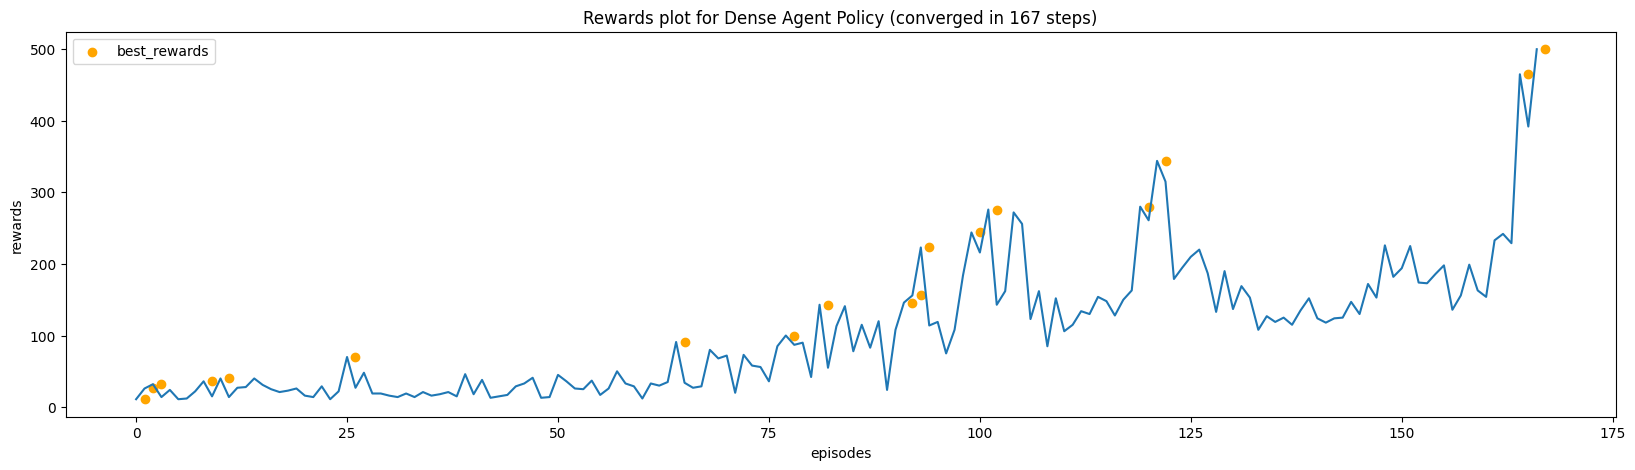

Training sparse policy with sparsity coef: 0.005



 25%|██▌       | 100/400 [02:28<07:24,  1.48s/it]


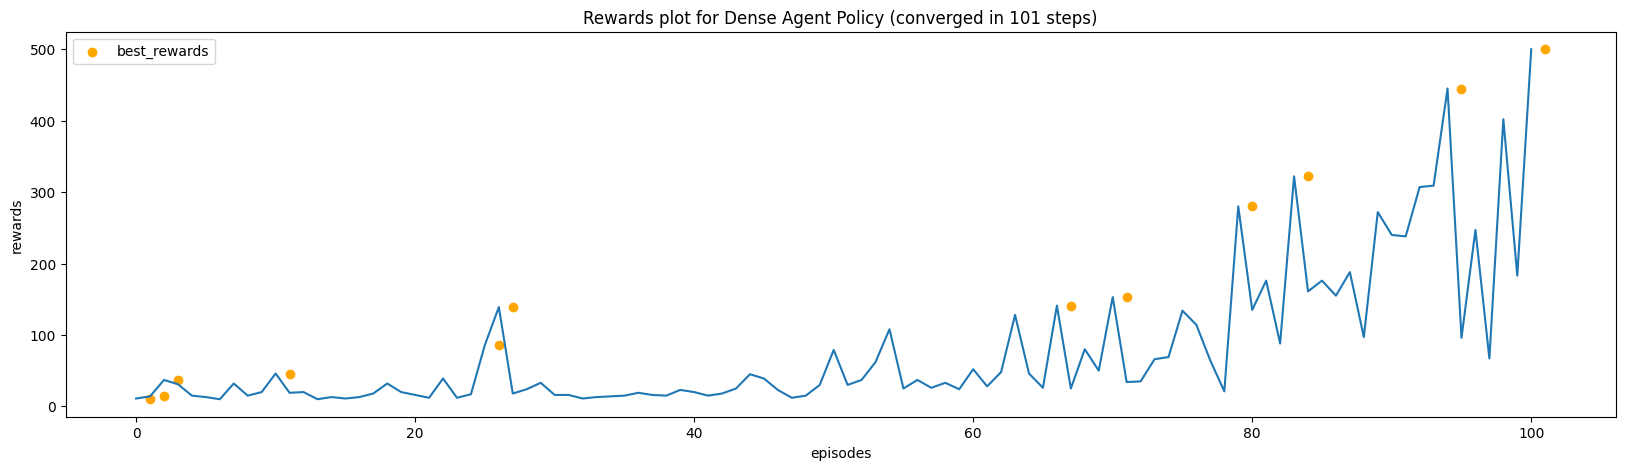

Training sparse policy with sparsity coef: 0.01



 18%|█▊        | 74/400 [01:54<08:24,  1.55s/it]


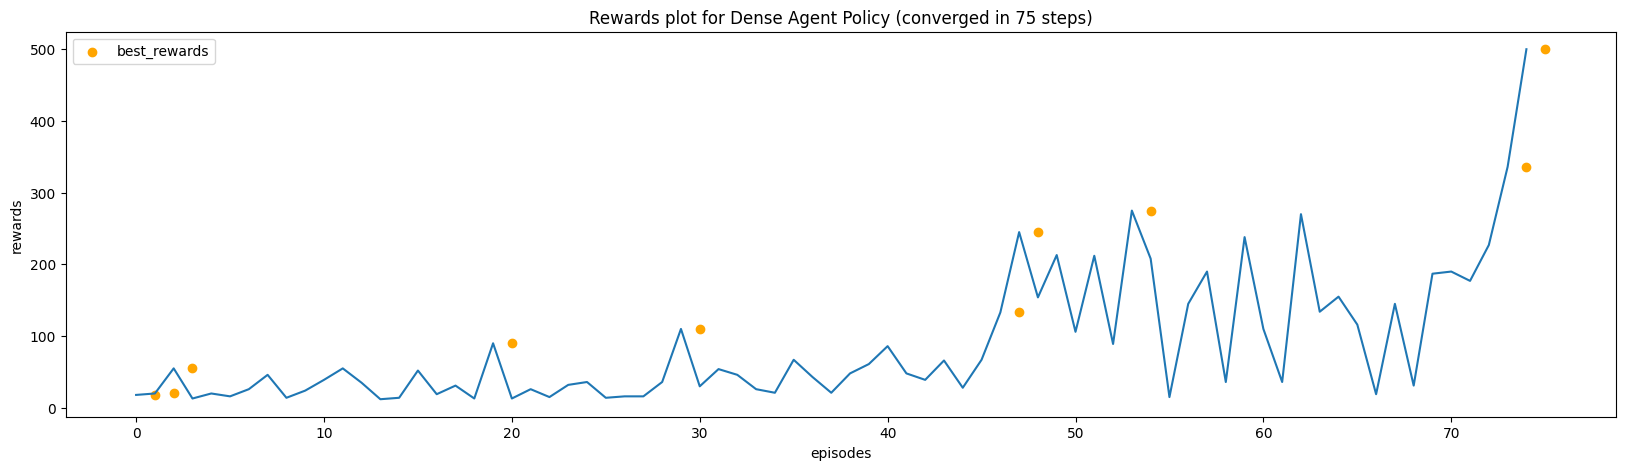

Training sparse policy with sparsity coef: 0.05



 14%|█▎        | 54/400 [01:13<07:52,  1.37s/it]


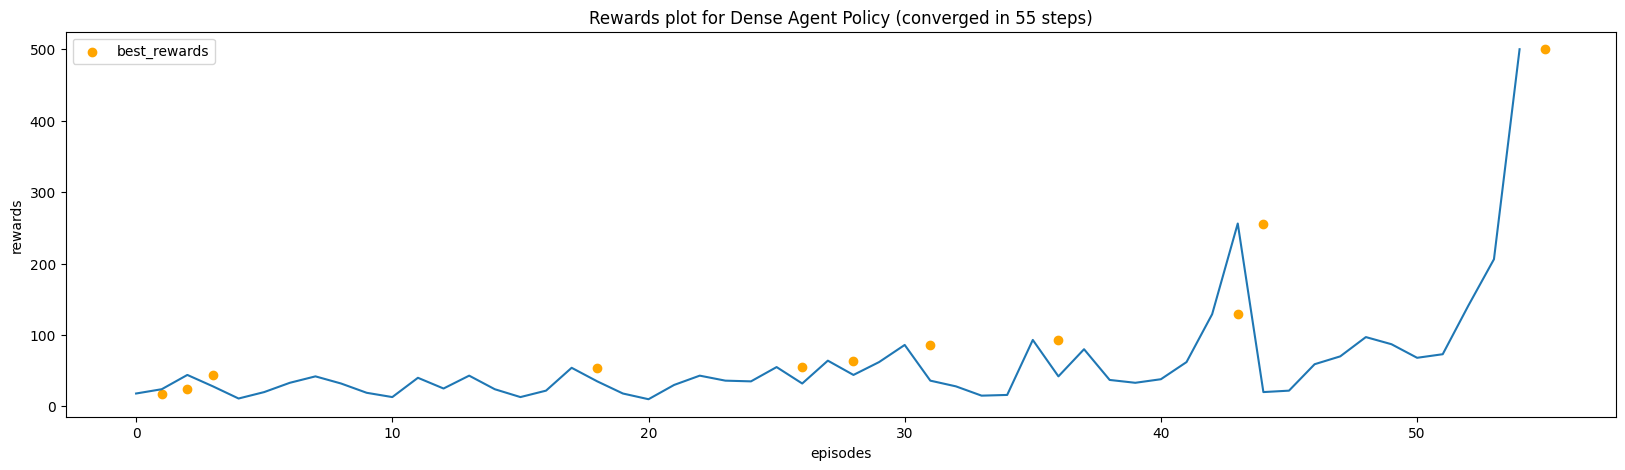

Training sparse policy with sparsity coef: 0.1



 17%|█▋        | 69/400 [01:40<08:03,  1.46s/it]


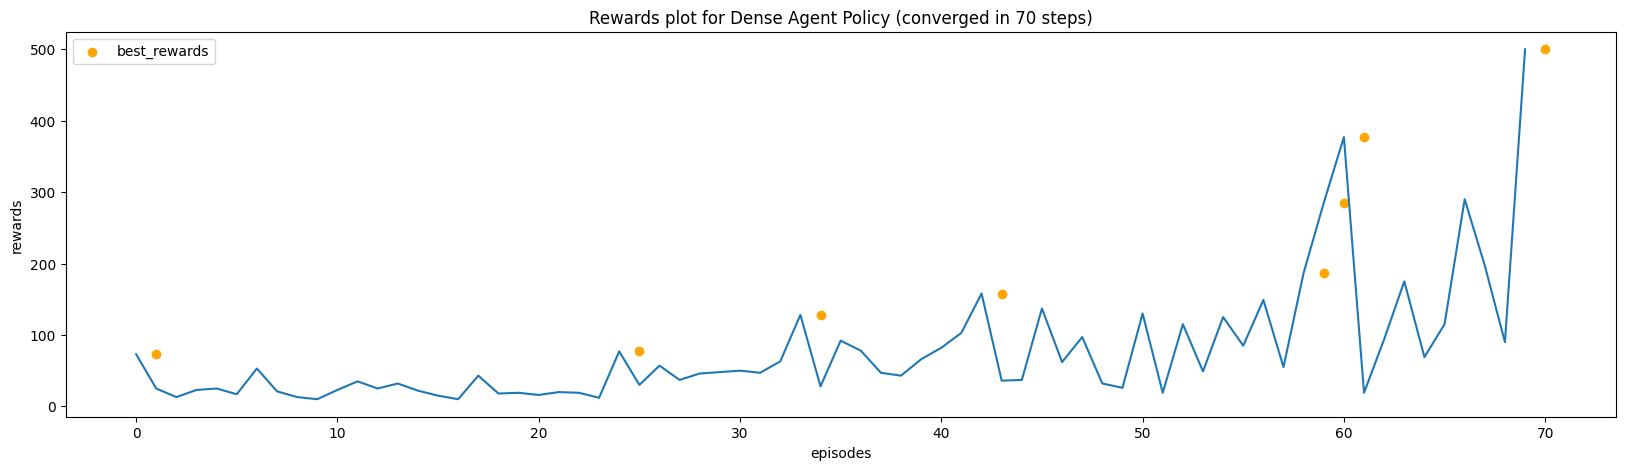

Training sparse policy with sparsity coef: 0.5



 46%|████▌     | 183/400 [04:55<05:50,  1.61s/it]


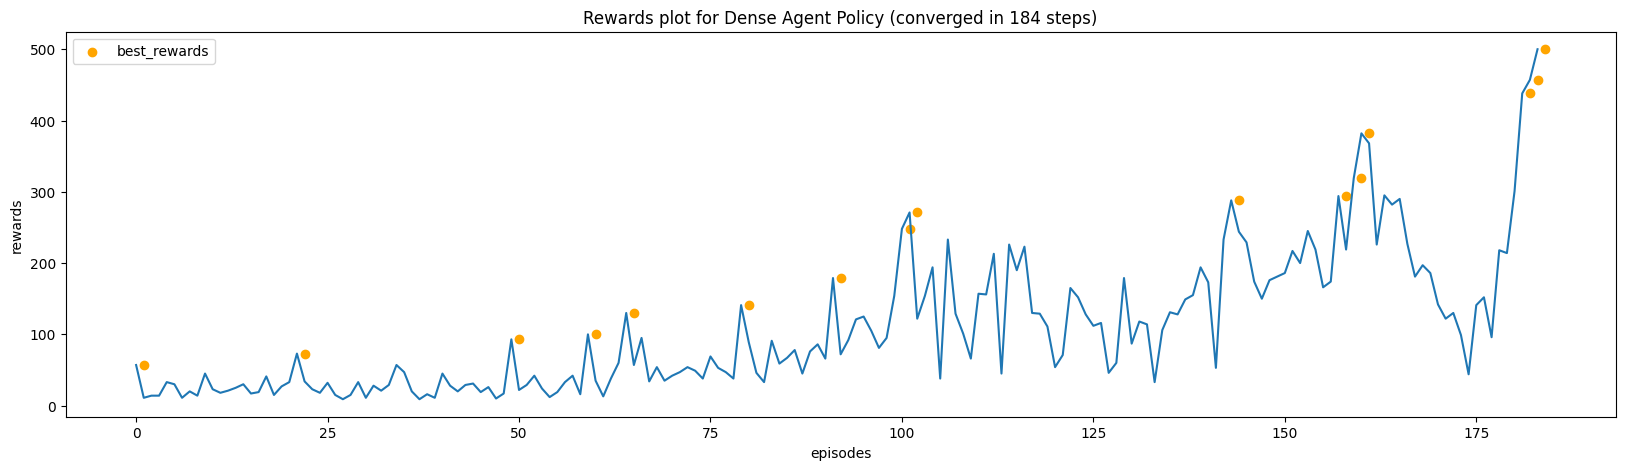

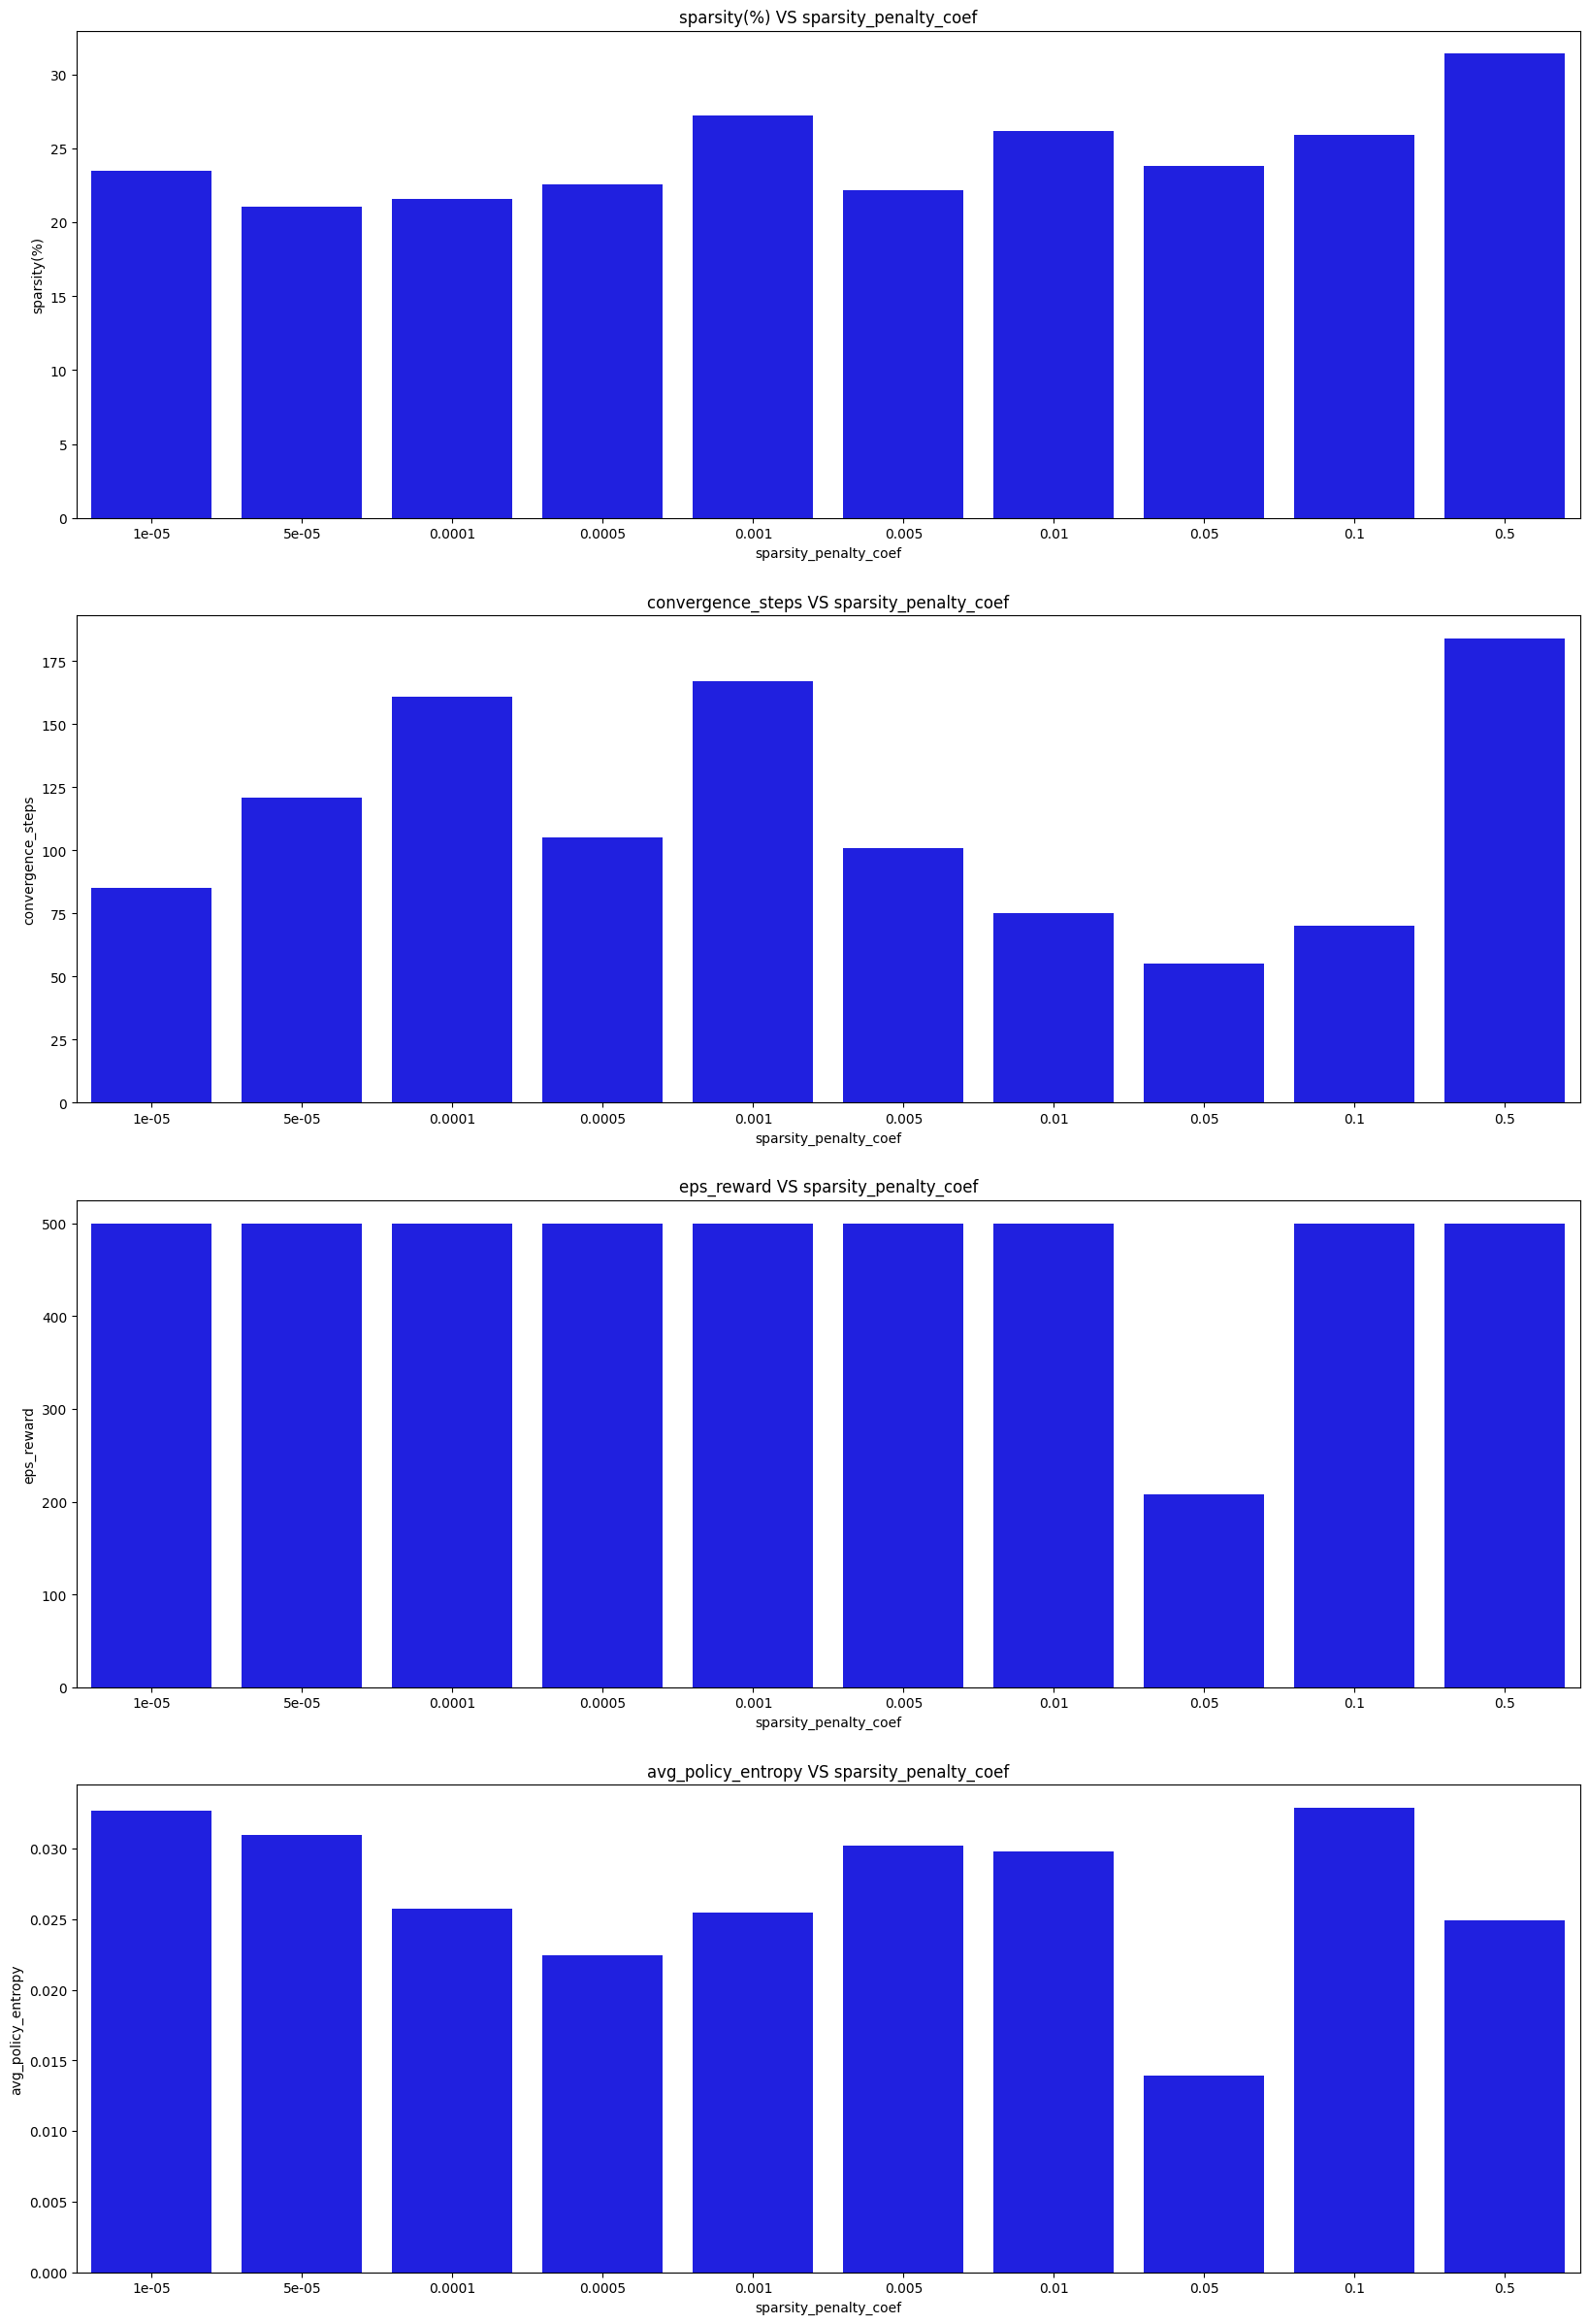

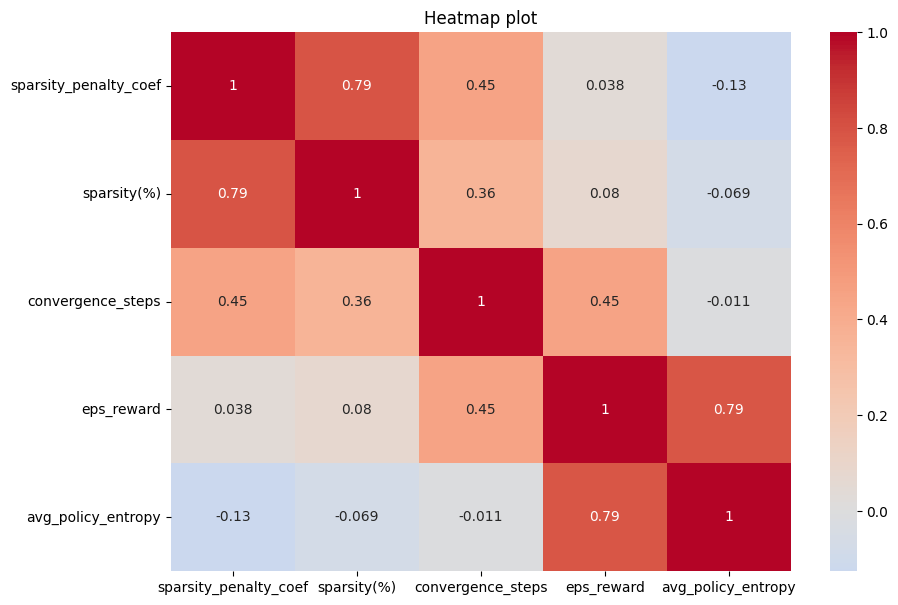

,sparsity_penalty_coef,sparsity(%),convergence_steps,eps_reward,avg_policy_entropy
0,0.00001,23.501587,85,500.0,0.032658
1,0.00005,21.044922,121,500.0,0.030992
2,0.00010,21.588135,161,500.0,0.025744
3,0.00050,22.583008,105,500.0,0.022438
4,0.00100,27.252197,167,500.0,0.025446
5,0.00500,22.192383,101,500.0,0.030242
6,0.01000,26.202393,75,500.0,0.029820
7,0.05000,23.831177,55,208.0,0.013937
8,0.10000,25.939941,70,500.0,0.032869
9,0.50000,31.399536,184,500.0,0.024886


In [7]:
result = dict()
result["sparsity_penalty_coef"] = []
result["sparsity(%)"] = []
result["convergence_steps"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []

policy_weights_filename = f"{env_name}_PPO_sparse_policy_agent.pth.tar"
best_score = -np.inf
best_model_idx = None

for idx, coef in enumerate(sparsity_penalty_coefs):
    sparse_policy_agent = SparsePolicyNet(observation_space, action_space, hidden_size, sparsity_on_eval=True)
    sparse_policy_agent.to(os.getenv("DEVICE"))
    sparse_value_agent = SparsePolicyNet(observation_space, 1, hidden_size, sparsity_on_eval=True)
    sparse_value_agent.to(os.getenv("DEVICE"))

    sparse_policy_agent.apply(xavier_init_weights)
    sparse_value_agent.apply(xavier_init_weights)

    sparse_policy_optimizer = torch.optim.Adam(sparse_policy_agent.parameters(), lr=policy_lr)
    sparse_value_optimizer = torch.optim.Adam(sparse_value_agent.parameters(), lr=value_lr)

    print(f"Training sparse policy with sparsity coef: {coef}\n")

    weights_filename = f"{idx}_{policy_weights_filename}"
    convergence_steps = run_train(
        sparse_policy_agent, 
        sparse_value_agent, 
        sparse_policy_optimizer, 
        sparse_value_optimizer, 
        weights_filename, 
        plot_performance=True,
        sparse_penalty_coef=coef
    )
    sparse_policy_agent.load_state_dict(torch.load(os.path.join(f"../params/{weights_filename}")))
    eps_reward, avg_policy_entropy = run_evaluation(
        gym.make(env_name, render_mode=RENDER_MODE_ON_EVAL), 
        sparse_policy_agent, 
        verbose=False
    )
    weight_sparsity = sparse_policy_agent.compute_weight_sparsity()[1] * 100
    score = eps_reward + weight_sparsity

    if score > best_score:
        best_score = score
        best_model_idx = idx

    result["sparsity_penalty_coef"].append(coef)
    result["sparsity(%)"].append(weight_sparsity)
    result["convergence_steps"].append(convergence_steps)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)

    del sparse_policy_agent, sparse_value_agent, sparse_policy_optimizer, sparse_value_optimizer
    gc.collect()
    torch.cuda.empty_cache()

unwanted_models = [
    f"../params/{i}_{policy_weights_filename}" for i in range(len(sparsity_penalty_coefs)) if i != best_model_idx
]

for i in range(len(sparsity_penalty_coefs)):
    if i == best_model_idx:
        os.rename(f"../params/{i}_{policy_weights_filename}", f"../params/{policy_weights_filename}")
        continue
    os.remove(f"../params/{i}_{policy_weights_filename}")

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="sparsity_penalty_coef", figsize=(20, 30))
os.makedirs(results_dir, exist_ok=True)
result.to_csv(os.path.join(results_dir, f"{env_name}_PPO_sparsification_results.csv"), index=False)
result